# Number of detected in-frame male crabs versus time

Two videos are plotted separately at their original frame times. **These are counts of male-targeted model detections, not ground-truth crab abundance or unique identities.** The main count is tracking-accepted detections (finite, in-image Shell, score >=0.5, duplicate-candidate rejection), including both land and water. This does not require a track to survive to a second frame.

The notebook reuses the full-resolution, validated per-frame count tables from `analyses/male_particle_eda_v001/run_15600144/`; it does not reload ~8 million observations or rerun SLEAP. The source is `datasets/v007_best_body_first_dataframe_v001`. Both videos have 28,800 frames at nominal 30000/1001 Hz.

**Execution on Della must be inside Slurm**, including interactive notebook kernels. The supplied `run.sh` executes this notebook in a finite CPU job. The saved outputs can be viewed without running a kernel. No GPU or model installation is needed to view them.


In [1]:
from pathlib import Path
import os, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

assert os.environ.get('SLURM_JOB_ID'), 'Execute this notebook in a Slurm-backed kernel on Della.'
%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'analyses/male_particle_eda_v001/run_15600144/COMPLETE.json').exists())
SOURCE = ROOT / 'analyses/male_particle_eda_v001/run_15600144'
OUTPUT = Path(os.environ.get('CRAB_COUNT_OUTPUT', ROOT / 'analyses/crab_counts_v001/figures'))
OUTPUT.mkdir(parents=True, exist_ok=True)
VIDEOS = ['Crab_Cam_2_2', 'Crab_Cam_2_3']
DT = 1001 / 30000
BIN_SECONDS = 10.0  # Change for a different display averaging interval.
COUNT_COLUMNS = ['raw', 'finite_in_image', 'accepted', 'land', 'water']
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def binned_counts(frame_table, bin_seconds=10.0):
    '''Nonoverlapping time-bin means of per-frame counts; zeros are retained.'''
    if not np.isfinite(bin_seconds) or bin_seconds <= 0:
        raise ValueError('bin_seconds must be finite and positive')
    groups = np.floor(frame_table.time_s.to_numpy() / bin_seconds).astype(np.int64)
    grouped = frame_table.groupby(groups, sort=True)
    result = grouped[['time_s', *COUNT_COLUMNS]].mean()
    result['n_frames'] = grouped.size()
    return result

def save_plot(fig, name):
    # Regression guard: no finite plotted count may fall outside its axis.
    for ax in fig.axes:
        low, high = ax.get_ylim()
        for line in ax.lines:
            y = np.asarray(line.get_ydata(), dtype=float)
            y = y[np.isfinite(y)]
            assert ((y >= low) & (y <= high)).all(), 'Clipped count curve'
    fig.savefig(OUTPUT / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(OUTPUT / f'{name}.pdf', bbox_inches='tight')


In [2]:
# Known-answer tests of the actual time-bin aggregation used in the figures.
toy = pd.DataFrame({'time_s': np.arange(5, dtype=float),
                    **{c: np.array([0, 2, 4, 6, 8]) for c in COUNT_COLUMNS}})
b = binned_counts(toy, 2)
np.testing.assert_allclose(b.accepted, [1, 5, 8])  # Includes a zero and partial final bin.
np.testing.assert_array_equal(b.n_frames, [2, 2, 1])
np.testing.assert_allclose(np.average(b.accepted, weights=b.n_frames), toy.accepted.mean())
constant = toy.copy(); constant[COUNT_COLUMNS] = 7
np.testing.assert_allclose(binned_counts(constant, 2)[COUNT_COLUMNS], 7)
for invalid in [0, -1, np.nan, np.inf]:
    try:
        binned_counts(toy, invalid)
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid bin width was accepted')
fig, ax = plt.subplots()
ax.plot([0, 1], [0, 3]); ax.set_ylim(0, 1)
try:
    save_plot(fig, 'intentionally_clipped_control')
except AssertionError as error:
    assert str(error) == 'Clipped count curve'
else:
    raise AssertionError('Plot clipping was not detected')
finally:
    plt.close(fig)
print('PASS: bin means/boundaries/zeros/partial bin; weighted mean conservation; constants; invalid widths; plot-clipping control.')


PASS: bin means/boundaries/zeros/partial bin; weighted mean conservation; constants; invalid widths; plot-clipping control.


In [3]:
receipt = json.loads((SOURCE / 'COMPLETE.json').read_text())
assert receipt['status'] == 'complete'
pins = {a['path']: a['sha256'] for a in receipt['artifacts']}
counts = {}
input_hashes = {}
for video in VIDEOS:
    relative = f'tables/{video}_counts.csv'
    path = SOURCE / relative
    digest = sha256(path)
    assert digest == pins[relative], f'Checksum mismatch: {video}'
    d = pd.read_csv(path)
    np.testing.assert_array_equal(d.frame, np.arange(28800))
    np.testing.assert_allclose(d.time_s, d.frame * DT, rtol=1e-12, atol=1e-12)
    values = d[COUNT_COLUMNS].to_numpy()
    assert np.isfinite(values).all() and (values >= 0).all()
    assert np.equal(values, np.floor(values)).all()
    assert (d.accepted <= d.finite_in_image).all() and (d.finite_in_image <= d.raw).all()
    np.testing.assert_array_equal(d.accepted, d.land + d.water)
    counts[video] = d
    input_hashes[video] = digest
assert sum(d.raw.sum() for d in counts.values()) == 7985830
assert sum(d.accepted.sum() for d in counts.values()) == 7957066
print('PASS: input checksums, all original frames, nominal times, integer nonnegative counts, selection nesting, land/water and total accounting.')
summary = pd.DataFrame([{
    'video': video, 'frames': len(d), 'duration_s': len(d) * DT,
    'mean_in_frame_detections': d.finite_in_image.mean(),
    'mean_accepted': d.accepted.mean(), 'min_accepted': d.accepted.min(),
    'max_accepted': d.accepted.max(), 'mean_land': d.land.mean(), 'mean_water': d.water.mean()
} for video, d in counts.items()]).set_index('video')
display(summary.round(3))
summary.to_csv(OUTPUT / 'count_summary.csv')


PASS: input checksums, all original frames, nominal times, integer nonnegative counts, selection nesting, land/water and total accounting.


,frames,duration_s,mean_in_frame_detections,mean_accepted,min_accepted,max_accepted,mean_land,mean_water
video,,,,,,,,
Crab_Cam_2_2,28800,960.96,127.511,127.152,93,161,121.095,6.057
Crab_Cam_2_3,28800,960.96,149.642,149.135,114,193,141.232,7.903


## 1. In-frame detection counts over time
The faint line uses **every frame**, not a subsample. The dark line is the mean number of accepted detections per frame in nonoverlapping 10-second time bins; it is **not** the sum of detections or the number of distinct tracklet IDs in a bin. Zero-count frames and the short final bin are retained. Bin locations are mean observed times.

Both land and water are included here. The two panels share a count scale; video times restart at zero independently.


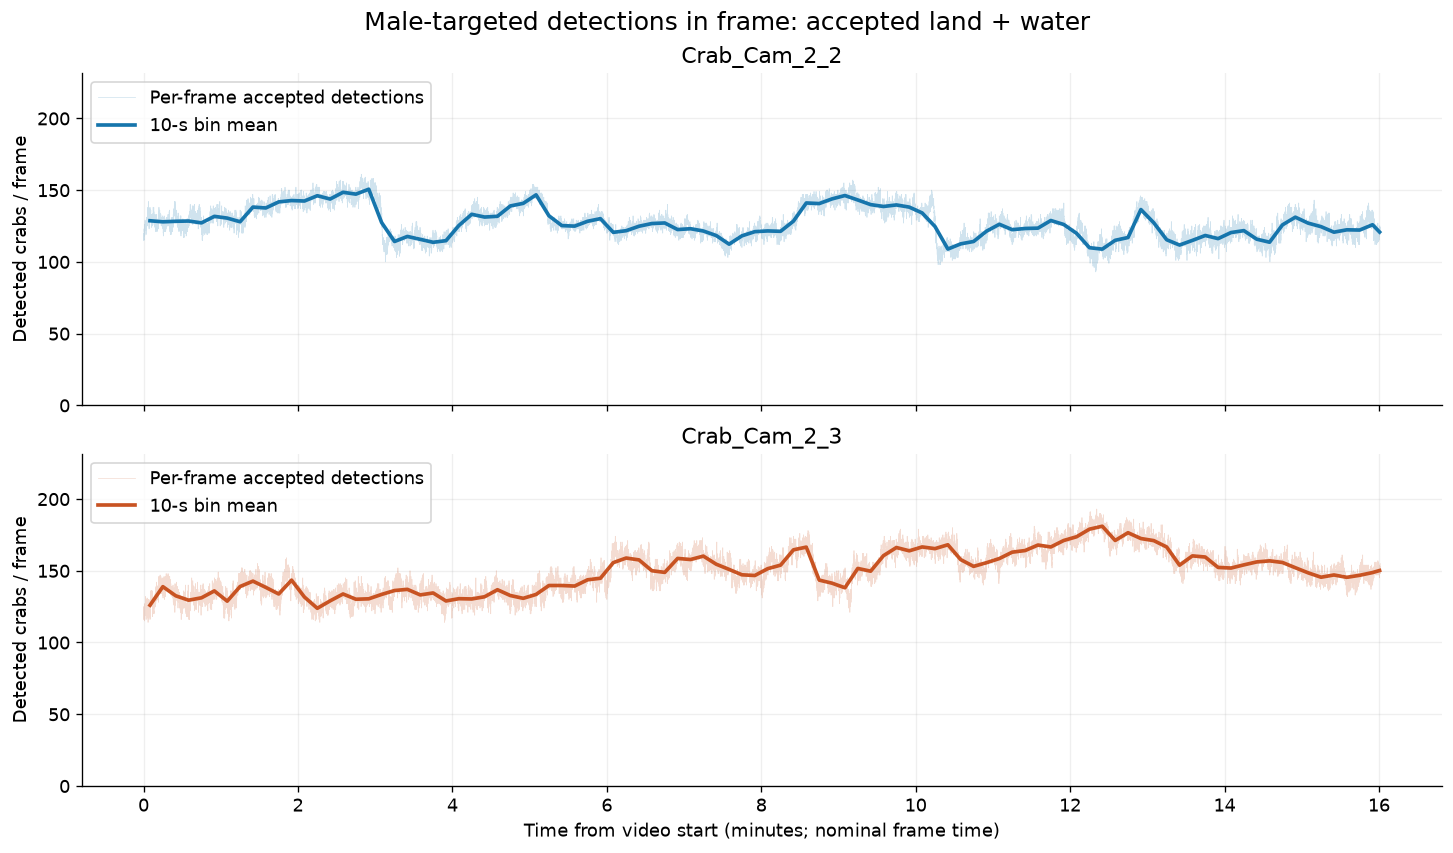

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True, layout='constrained')
for ax, (video, d), color in zip(axes, counts.items(), ['#1675ac', '#c85322']):
    b = binned_counts(d, BIN_SECONDS)
    ax.plot(d.time_s / 60, d.accepted, color=color, alpha=0.20, linewidth=0.45,
            rasterized=True, label='Per-frame accepted detections')
    ax.plot(b.time_s / 60, b.accepted, color=color, linewidth=2.2,
            label=f'{BIN_SECONDS:g}-s bin mean')
    ax.set(title=video, ylabel='Detected crabs / frame')
    ax.grid(alpha=0.2); ax.legend(loc='upper left')
    b.to_csv(OUTPUT / f'{video}_binned_counts.csv', index_label='time_bin')
axes[0].set_ylim(0, 1.20 * max(d.accepted.max() for d in counts.values()))
axes[-1].set_xlabel('Time from video start (minutes; nominal frame time)')
fig.suptitle('Male-targeted detections in frame: accepted land + water', fontsize=15)
save_plot(fig, 'in_frame_crab_counts')
plt.show()


## 2. What changes when we filter detections?
- **All finite in-image Shell positions:** the literal in-frame coordinate selection, without a score or tracking-acceptance filter.
- **Tracking accepted:** the primary quality-filtered count, including singleton detections.
- **Accepted land / water:** subsets using the existing fixed water polygon; this is not frame-by-frame water segmentation.
- **Raw:** all model outputs, including missing/out-of-image Shell coordinates, shown only as an accounting reference.

False/missed detections, unresolved duplicates and reflection-like detections remain possible. Counting observations in a frame avoids treating fragmented tracklet IDs as new animals, but it does not establish a true animal census.


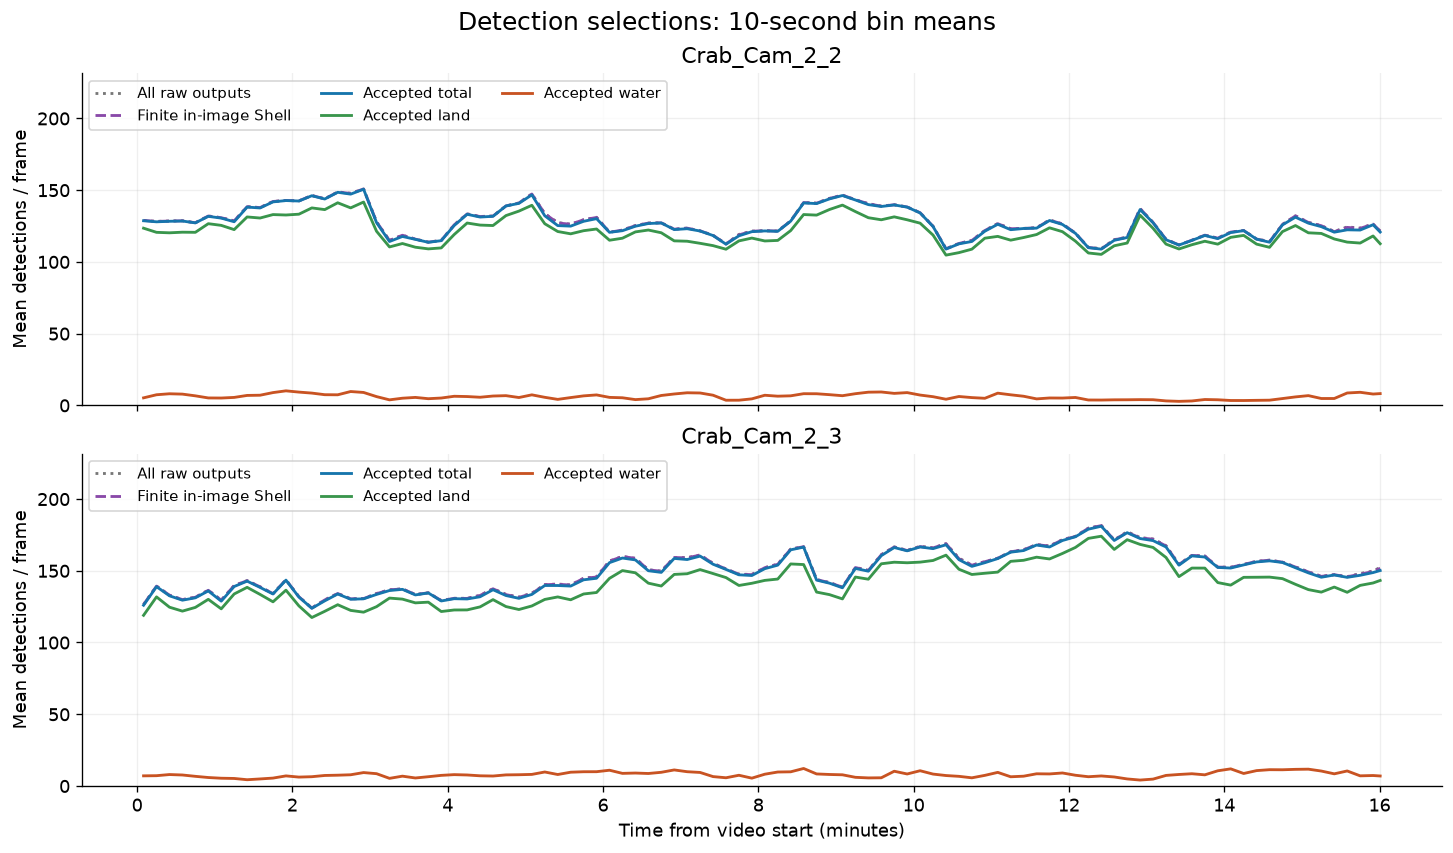

Figures and summary saved to: /scratch/gpfs/WBIALEK/db8682/fiddler_crab_sleap/analyses/crab_counts_v001/run_15635974/figures


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True, layout='constrained')
styles = [('raw', 'All raw outputs', '#777777', ':'),
          ('finite_in_image', 'Finite in-image Shell', '#8949a8', '--'),
          ('accepted', 'Accepted total', '#1675ac', '-'),
          ('land', 'Accepted land', '#39954c', '-'),
          ('water', 'Accepted water', '#c85322', '-')]
for ax, (video, d) in zip(axes, counts.items()):
    b = binned_counts(d, BIN_SECONDS)
    for column, label, color, linestyle in styles:
        ax.plot(b.time_s / 60, b[column], label=label, color=color, linestyle=linestyle, linewidth=1.7)
    ax.set(title=video, ylabel='Mean detections / frame')
    ax.grid(alpha=0.2); ax.legend(ncol=3, fontsize=9, loc='upper left')
axes[0].set_ylim(0, 1.20 * max(d.raw.max() for d in counts.values()))
axes[-1].set_xlabel('Time from video start (minutes)')
fig.suptitle(f'Detection selections: {BIN_SECONDS:g}-second bin means', fontsize=15)
save_plot(fig, 'count_selection_comparison')
plt.show()

provenance = {'source_analysis_job': '15600144', 'notebook_job': os.environ['SLURM_JOB_ID'],
              'count_csv_sha256': input_hashes, 'source_completion_sha256': sha256(SOURCE / 'COMPLETE.json'),
              'frame_interval_s': DT, 'bin_seconds': BIN_SECONDS,
              'tests_and_data_validations_passed': True,
              'count_definition': 'accepted per-frame detections including singleton tracklets and water'}
(OUTPUT / 'count_provenance.json').write_text(json.dumps(provenance, indent=2))
print(f'Figures and summary saved to: {OUTPUT}')


## Reading these plots
The previous analysis found average accepted totals of about **127.2** and **149.1** detections/frame (land-only means about **121.1** and **141.2**). The summary above recomputes these quantities from the complete saved per-frame series.

Changes over time may reflect animals entering/leaving the view, emerging/hiding, visibility or detection performance. These data alone cannot distinguish those mechanisms. No statistical comparison between independent populations is implied by comparing the two videos.

For visualization of the actual poses, see `docs/VISUALIZING_PREDICTIONS.md`. For dataset semantics, see `docs/datasets/v007_best_body_first_dataframe_v001/README.md`. This notebook uses existing count tables without changing any original dataset or prediction artifact.
